# Лабораторная работа №4. Эмбеддинги, рекуррентные сети и трансформеры

Датасет и разбиение те же, что в лабораторных 1-3: AG News, 120 000 новостей четырёх классов (World, Sports, Business, Sci/Tech), Train и Test в пропорции 80 на 20 со стратификацией, `random_state=42`. Поэтому результаты Naive Bayes и SVM из третьей работы можно прямо сравнивать с новыми моделями.

Что делаю:
1. Обучаю Word2Vec, смотрю на ближайшие слова и строю карту t-SNE.
2. Делаю baseline: усредняю векторы слов и обучаю логистическую регрессию.
3. Строю BiLSTM в двух вариантах слоя Embedding: static и dynamic.
4. Обучаю её с Early Stopping и смотрю на графики.
5. Выбираю предобученный трансформер.
6. Дообучаю его на подвыборке.
7. Собираю все модели курса в одну таблицу.
8. Пишу вывод.

In [2]:
import re, html, time, copy, unicodedata, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
#from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, classification_report

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    return {'precision': p, 'recall': r, 'f1': f, 'accuracy': accuracy_score(y_true, y_pred)}

## 0. Данные

Загружаю AG News и делю на Train и Test так же, как в прошлых работах.

In [3]:
LABEL_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}

try:
    from datasets import load_dataset
    raw = load_dataset('fancyzhx/ag_news')
    df = pd.DataFrame(raw['train'])
    df['label'] = df['label'] + 1
    source = 'Hugging Face'
except Exception as e:
    URL = 'https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv'
    df = pd.read_csv(URL, header=None, names=['label', 'title', 'description'])
    df['text'] = df['title'] + ' ' + df['description']
    source = 'GitHub CSV (запасной источник)'

df['category'] = df['label'].map(LABEL_MAP)

train_df, test_df = train_test_split(
    df[['text', 'label', 'category']], test_size=0.2,
    random_state=RANDOM_STATE, stratify=df['label'])
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Train:', train_df.shape, ' Test:', test_df.shape)
print('Среднее число слов в Train:', round(train_df['text'].str.split().str.len().mean(), 1))
print('Первый документ Train:', train_df['text'].iloc[0][:90])
print()
print(pd.concat([train_df['category'].value_counts().rename('Train'),
                 test_df['category'].value_counts().rename('Test')], axis=1))

Train: (96000, 3)  Test: (24000, 3)
Среднее число слов в Train: 37.9
Первый документ Train: Clijsters Unsure About Latest Injury, Says Hewitt  TOKYO (Reuters) - Belgian Kim Clijsters

          Train  Test
category             
Sports    24000  6000
Sci/Tech  24000  6000
World     24000  6000
Business  24000  6000


Для Word2Vec и сети нужны очищенные тексты в виде списков слов. Беру функцию `tokenize` из третьей работы: нижний регистр, без знаков препинания, числа, ссылки и почта заменены на `num`, `url`, `email`.

In [4]:
RE_HTML_TAG = re.compile(r'<[^>]+>')
RE_ENTITY_NO_AMP = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
RE_URL = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
RE_EMAIL = re.compile(r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b')
RE_NUMBER = re.compile(r'(?<![A-Za-z\-.,])\b\d+([.,]\d+)*\b(?![A-Za-z\-])')
RE_BACKSLASH = re.compile(r'\\+')
RE_TOKEN = re.compile(r'\[(?:NUM|URL|EMAIL)\]|\w+(?:[-.]\w+)*|[^\w\s]')
SERVICE = {'[NUM]': 'num', '[URL]': 'url', '[EMAIL]': 'email'}


def tokenize(text):
    """Очистка из лабораторной 1 + нижний регистр, без знаков препинания."""
    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub('[URL]', text)
    text = RE_EMAIL.sub('[EMAIL]', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', errors='ignore').decode('ascii')
    text = RE_NUMBER.sub('[NUM]', text)
    text = RE_BACKSLASH.sub(' ', text)
    tokens = []
    for t in RE_TOKEN.findall(text):
        if t in SERVICE:
            tokens.append(SERVICE[t])
        elif re.search('[A-Za-z]', t):
            tokens.append(t.lower())
    return tokens


for d in (train_df, test_df):
    d['tokens'] = d['text'].map(tokenize)
    d['text_clean'] = d['tokens'].map(' '.join)

print(train_df['text'].iloc[1])
print(train_df['text_clean'].iloc[1])

Earthquake Swarm Shakes Eastern Sierra (AP) AP - A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remote, sparsely populated area along the eastern Sierra Nevada on Saturday, authorities said.
earthquake swarm shakes eastern sierra ap ap a swarm of earthquakes one a magnitude-5.5 jolted a remote sparsely populated area along the eastern sierra nevada on saturday authorities said


## 1. Word2Vec

Обучаю Word2Vec на текстах из Train (метки ему не нужны, Test не трогаю). Использую skip-gram: по слову модель учится предсказывать его соседей. Параметры: вектор из 100 чисел, окно 5 слов, слова реже пяти раз отбрасываю, на каждую настоящую пару 10 случайных неправильных (negative sampling), 8 эпох.

In [ ]:
t0 = time.time()
w2v = Word2Vec(sentences=train_df['tokens'].tolist(), vector_size=100, window=5, min_count=5,
               sg=1, negative=10, epochs=8, workers=2, seed=RANDOM_STATE)
w2v_time = time.time() - t0
wv = w2v.wv
print(f'Word2Vec обучен за {w2v_time:.0f} с')
print('Размер словаря:', len(wv), ' размерность вектора:', wv.vector_size)

Word2Vec обучен за 162 с
Размер словаря: 26088  размерность вектора: 100


Для пяти слов из разных тем нахожу пять ближайших соседей по косинусной близости.

In [ ]:
KEYWORDS = ['oil', 'microsoft', 'olympic', 'iraq', 'nasa']
rows = []
for w in KEYWORDS:
    for rank, (neighbor, sim) in enumerate(wv.most_similar(w, topn=5), 1):
        rows.append({'слово': w, 'место': rank, 'сосед': neighbor, 'косинусная близость': round(float(sim), 3)})
nn_df = pd.DataFrame(rows)
display(nn_df.pivot(index='слово', columns='место', values='сосед').loc[KEYWORDS])
display(nn_df.pivot(index='слово', columns='место', values='косинусная близость').loc[KEYWORDS])

место,1,2,3,4,5
слово,,,,,
oil,crude,spr,crude-oil,prices,petroleum
microsoft,msft,microsofts,windows,msft.o,redmond
olympic,athens,olympics,medal,paralympic,medals
iraq,iraqi,baghdad,iraqis,allawi,iraqs
nasa,shuttle,robotic,spacecraft,nasas,hubble


место,1,2,3,4,5
слово,,,,,
oil,0.870,0.728,0.712,0.712,0.708
microsoft,0.795,0.754,0.754,0.734,0.695
olympic,0.865,0.845,0.835,0.786,0.784
iraq,0.844,0.784,0.744,0.731,0.727
nasa,0.764,0.755,0.753,0.750,0.745


Соседи по теме. У `oil` это `crude`, `prices`, `petroleum`, у `nasa` это `shuttle`, `spacecraft`, `hubble`, у `microsoft` это `msft`, `windows`, `redmond`. Попадаются и просто другие формы того же слова (`medal` и `medals`, `iraqi` и `iraqis`): лемматизацию я не делала, и Word2Vec сам понял, что они близки.

Для карты беру 120 слов: по 30 самых характерных для каждого класса. Слово подходит, если оно есть минимум в 300 документах и не меньше 75% этих документов относятся к одному классу. Метки нужны только для выбора слов и цвета точек, сами векторы обучены без них. Размерность со 100 до 2 снижаю алгоритмом t-SNE.

Подходящих слов: 294  выбрано для карты: 120


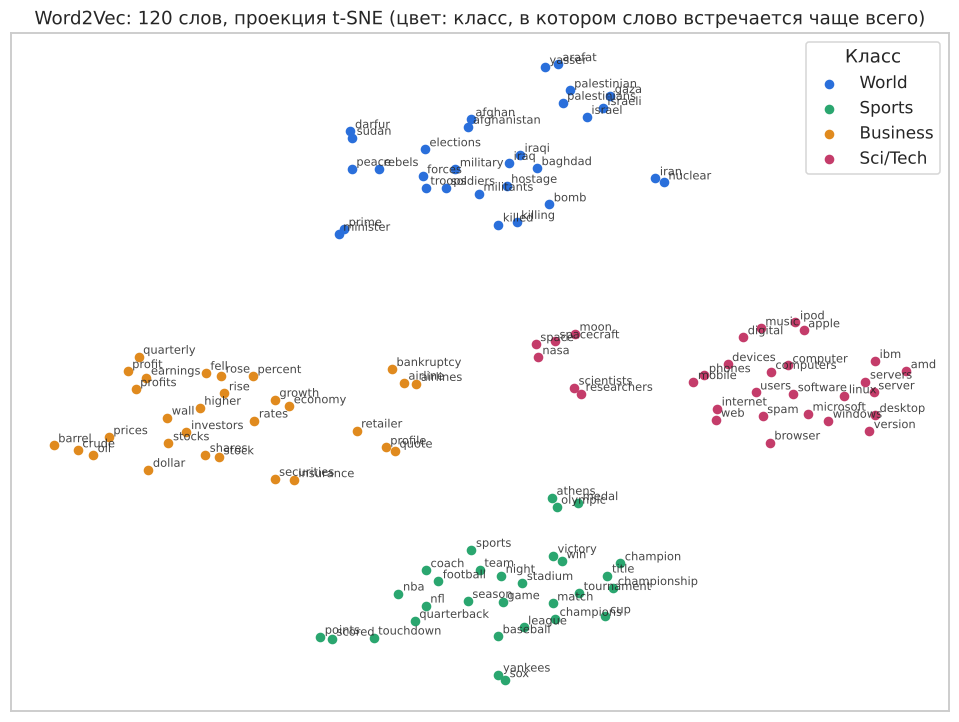

In [ ]:
doc_count = defaultdict(lambda: np.zeros(4))
for toks, lab in zip(train_df['tokens'], train_df['label']):
    for t in set(toks):
        doc_count[t][lab - 1] += 1

STOP = set('the a an of to in and for on at with by from as is was are be that this it its his her he she they their '
           'has have had will would said says say new after over more about up out one two first'.split())
rows = []
for w, c in doc_count.items():
    n = c.sum()
    if n >= 300 and w in wv.key_to_index and w not in STOP and w.isalpha() and len(w) > 2 and c.max() / n >= 0.75:
        rows.append((w, int(n), int(c.argmax()) + 1, c.max() / n))
cand = pd.DataFrame(rows, columns=['word', 'docs', 'cls', 'share'])
cand['score'] = cand['share'] * np.log(cand['docs'])
sel = pd.concat([g.sort_values('score', ascending=False).head(30) for _, g in cand.groupby('cls')]).reset_index(drop=True)
print('Подходящих слов:', len(cand), ' выбрано для карты:', len(sel))

V = np.vstack([wv[w] for w in sel['word']])
Z = TSNE(n_components=2, perplexity=15, init='pca', learning_rate='auto', random_state=RANDOM_STATE).fit_transform(V)

colors = {1: '#2a6fdb', 2: '#2aa66f', 3: '#e08a1e', 4: '#c43c6a'}
fig, ax = plt.subplots(figsize=(11, 8))
for c in (1, 2, 3, 4):
    m = (sel['cls'] == c).values
    ax.scatter(Z[m, 0], Z[m, 1], c=colors[c], label=LABEL_MAP[c], s=28)
for (x, y), w in zip(Z, sel['word']):
    ax.annotate(w, (x, y), fontsize=7.5, alpha=0.85, xytext=(3, 2), textcoords='offset points')
ax.set_title('Word2Vec: 120 слов, проекция t-SNE (цвет: класс, в котором слово встречается чаще всего)')
ax.legend(title='Класс')
ax.set_xticks([]); ax.set_yticks([])
plt.show()

Слова разошлись на четыре группы, и они совпадают с классами. Внутри групп тоже видна структура. В Sports отдельно командные виды (`nba`, `nfl`, `yankees`) и Олимпиада. В World отдельно Ближний Восток (`gaza`, `israel`, `arafat`) и военные слова (`troops`, `baghdad`). В Sci/Tech компьютерные слова (`software`, `linux`, `server`) и космос (`nasa`, `spacecraft`, `moon`). В Business нефть (`oil`, `crude`, `barrel`) отдельно от отчётности (`profit`, `earnings`) и авиакомпаний. Одна оговорка: t-SNE сохраняет только близость соседей, а расстояния между группами на таком графике смотреть не стоит.

## 2. Baseline: усреднение векторов слов

Вектор документа это среднее векторов его слов (тех, что есть в словаре Word2Vec). Порядок слов при этом теряется, зато вместо 42 тысяч разреженных признаков получается 100 плотных. На них обучаю логистическую регрессию, параметр `C` подбираю кросс-валидацией на Train (3 фолда, macro F1), как в третьей работе.

In [ ]:
def doc_vec(tokens):
    vecs = [wv[t] for t in tokens if t in wv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size, dtype=np.float32)

t0 = time.time()
Xtr_w2v = np.vstack(train_df['tokens'].map(doc_vec))
Xte_w2v = np.vstack(test_df['tokens'].map(doc_vec))
pool_time = time.time() - t0
y_train = train_df['label'].values
y_test = test_df['label'].values
print('Матрицы признаков:', Xtr_w2v.shape, Xte_w2v.shape, f' (усреднение {pool_time:.1f} с)')
print('Документов без единого известного слова в Train:', int((np.abs(Xtr_w2v).sum(axis=1) == 0).sum()))

lr_search = GridSearchCV(LogisticRegression(max_iter=1000), {'C': [0.1, 1, 10]},
                         scoring='f1_macro', cv=3, n_jobs=1)
lr_search.fit(Xtr_w2v, y_train)
print(pd.DataFrame({'C': lr_search.cv_results_['param_C'], 'macro F1 (CV)': lr_search.cv_results_['mean_test_score'].round(4)}).to_string(index=False))
print('Лучшее:', lr_search.best_params_)

t0 = time.time()
lr = LogisticRegression(C=lr_search.best_params_['C'], max_iter=1000).fit(Xtr_w2v, y_train)
lr_time = time.time() - t0
m_lr = evaluate(y_test, lr.predict(Xte_w2v))
print(f'\nОбучение за {lr_time:.1f} с')
print(pd.Series(m_lr).round(4).to_string())

Матрицы признаков: (96000, 100) (24000, 100)  (усреднение 5.7 с)
Документов без единого известного слова в Train: 0


   C  macro F1 (CV)
 0.1         0.8895
 1.0         0.8911
10.0         0.8908
Лучшее: {'C': 1}



Обучение за 2.0 с
precision    0.8935
recall       0.8937
f1           0.8935
accuracy     0.8937


Macro F1 на Test получился 0,8935, заметно ниже, чем у LinearSVC на TF-IDF (0,9225). Скорее всего, при усреднении характерные слова документа (названия компаний, имена) растворяются среди десятков общих слов, а в TF-IDF каждое слово остаётся отдельным признаком. Сама регрессия обучается за 2 секунды, основное время ушло на Word2Vec (около 170 секунд).

## 3. BiLSTM: static и dynamic

Сеть читает документ слово за словом в обе стороны, поэтому учитывает порядок слов, а ни мешок слов, ни усреднение этого не делают. Слои по порядку: Embedding (слово превращается в вектор из 100 чисел), BiLSTM со 128 нейронами в каждую сторону, max-pooling по словам документа, Dropout 0,3 и линейный слой на 4 класса.

Два режима слоя Embedding:
- static: веса берутся из Word2Vec и замораживаются (`requires_grad=False`, в коде `freeze=True`);
- dynamic: слой создаётся со случайными весами и учится вместе с сетью.

Словарь у обоих режимов одинаковый: слова из Word2Vec, остальные заменяются на `<unk>`. Документы обрезаю или дополняю до 64 слов.

In [ ]:
MAXLEN = 64
itos = ['<pad>', '<unk>'] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}

def encode(tokens):
    ids = [stoi.get(t, 1) for t in tokens[:MAXLEN]]
    return ids + [0] * (MAXLEN - len(ids))

X_all = torch.tensor([encode(t) for t in train_df['tokens']])
y_all = torch.tensor(y_train - 1)
X_te = torch.tensor([encode(t) for t in test_df['tokens']])
y_te = torch.tensor(y_test - 1)

n_tokens = sum(min(len(t), MAXLEN) for t in train_df['tokens'])
n_unk = int((X_all == 1).sum())
print('Размер словаря сети:', len(itos))
print(f'Доля токенов <unk> в Train: {n_unk / n_tokens:.2%}')
print(f'Документов длиннее {MAXLEN} токенов (обрезаются): {(train_df["tokens"].map(len) > MAXLEN).mean():.1%}')

# validation: 10% Train, по ней работает Early Stopping
idx_tr, idx_val = train_test_split(np.arange(len(X_all)), test_size=0.1, random_state=RANDOM_STATE,
                                   stratify=y_train)
X_tr, y_tr = X_all[idx_tr], y_all[idx_tr]
X_val, y_val = X_all[idx_val], y_all[idx_val]
print('Обучающая часть:', len(X_tr), ' validation:', len(X_val), ' test:', len(X_te))

# матрица для static-режима: <pad> нули, <unk> средний вектор
emb_matrix = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
emb_matrix[2:] = wv.vectors
emb_matrix[1] = wv.vectors.mean(axis=0)

Размер словаря сети: 26090
Доля токенов <unk> в Train: 2.15%
Документов длиннее 64 токенов (обрезаются): 1.7%
Обучающая часть: 86400  validation: 9600  test: 24000


In [ ]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, static):
        super().__init__()
        if static:
            self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
        else:
            self.emb = nn.Embedding(len(itos), wv.vector_size, padding_idx=0)
        self.rnn = nn.LSTM(wv.vector_size, 128, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(256, 4)

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        h, _ = self.rnn(self.emb(x))
        h = h.masked_fill(~mask, -1e9).max(dim=1).values   # max-pooling, <pad> не учитываем
        return self.fc(self.drop(h))

for static in (True, False):
    m = BiLSTMClassifier(static)
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{"Static " if static else "Dynamic"}: параметров всего {total:,}, обучаемых {trainable:,}')

Static : параметров всего 2,845,548, обучаемых 236,548
Dynamic: параметров всего 2,845,548, обучаемых 2,845,548


Параметров в обеих сетях поровну, около 2,85 млн, но в static обучаются только LSTM и линейный слой (около 237 тысяч), а в dynamic ещё и 2,6 млн весов эмбеддингов. Эту разницу нужно иметь в виду при сравнении режимов.

## 4. Обучение RNN

Оптимизатор Adam (`lr=2e-3`), батч 256, максимум 8 эпох. После каждой эпохи считаю Loss и macro F1 на обучающей части и на validation. Early Stopping работает по validation Loss: если 2 эпохи подряд он не улучшается, обучение останавливается, а в модель возвращаются веса лучшей эпохи. Метрики на обучающей части считаются по ходу эпохи с включённым Dropout, поэтому немного занижены.

In [ ]:
@torch.no_grad()
def predict_logits(model, X, bs=1024):
    model.eval()
    return torch.cat([model(X[i:i + bs].to(DEVICE)).cpu() for i in range(0, len(X), bs)])


def train_rnn(static, max_epochs=8, patience=2, lr=2e-3, bs=256):
    torch.manual_seed(RANDOM_STATE)
    model = BiLSTMClassifier(static).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
    best_val, best_state, best_epoch, bad = float('inf'), None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X_tr))
        loss_sum, preds, labels = 0.0, [], []
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = X_tr[idx].to(DEVICE), y_tr[idx].to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = nn.functional.cross_entropy(logits, yb)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * len(idx)
            preds.append(logits.argmax(1).cpu())
            labels.append(yb.cpu())
        tr_loss = loss_sum / len(X_tr)
        tr_f1 = f1_score(torch.cat(labels).numpy(), torch.cat(preds).numpy(), average='macro')
        val_logits = predict_logits(model, X_val)
        val_loss = nn.functional.cross_entropy(val_logits, y_val).item()
        val_f1 = f1_score(y_val.numpy(), val_logits.argmax(1).numpy(), average='macro')
        for k, v in zip(hist, (tr_loss, val_loss, tr_f1, val_f1)):
            hist[k].append(v)
        print(f'эпоха {epoch}: train loss {tr_loss:.4f} F1 {tr_f1:.4f} | val loss {val_loss:.4f} F1 {val_f1:.4f} | {time.time() - t0:.0f} с')
        if val_loss < best_val - 1e-4:
            best_val, best_epoch, bad = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f'Early Stopping: validation loss не улучшается {patience} эпохи подряд, лучшая эпоха {best_epoch}')
                break
    model.load_state_dict(best_state)
    return model, hist, best_epoch, time.time() - t0


rnn = {}
for static in (True, False):
    name = 'BiLSTM static' if static else 'BiLSTM dynamic'
    print('=' * 20, name, '=' * 20)
    rnn[name] = train_rnn(static)

==================== BiLSTM static ====================


эпоха 1: train loss 0.3879 F1 0.8675 | val loss 0.3035 F1 0.8981 | 97 с


эпоха 2: train loss 0.2879 F1 0.9014 | val loss 0.2766 F1 0.9049 | 193 с


эпоха 3: train loss 0.2666 F1 0.9077 | val loss 0.2620 F1 0.9105 | 291 с


эпоха 4: train loss 0.2510 F1 0.9123 | val loss 0.2520 F1 0.9113 | 389 с


эпоха 5: train loss 0.2386 F1 0.9163 | val loss 0.2438 F1 0.9158 | 484 с


... (4 outputs left out)

эпоха 2: train loss 0.2760 F1 0.9070 | val loss 0.2866 F1 0.9036 | 199 с


эпоха 3: train loss 0.2102 F1 0.9287 | val loss 0.2818 F1 0.9067 | 295 с


эпоха 4: train loss 0.1616 F1 0.9455 | val loss 0.2844 F1 0.9081 | 404 с


эпоха 5: train loss 0.1230 F1 0.9587 | val loss 0.3089 F1 0.9051 | 516 с
Early Stopping: validation loss не улучшается 2 эпохи подряд, лучшая эпоха 3


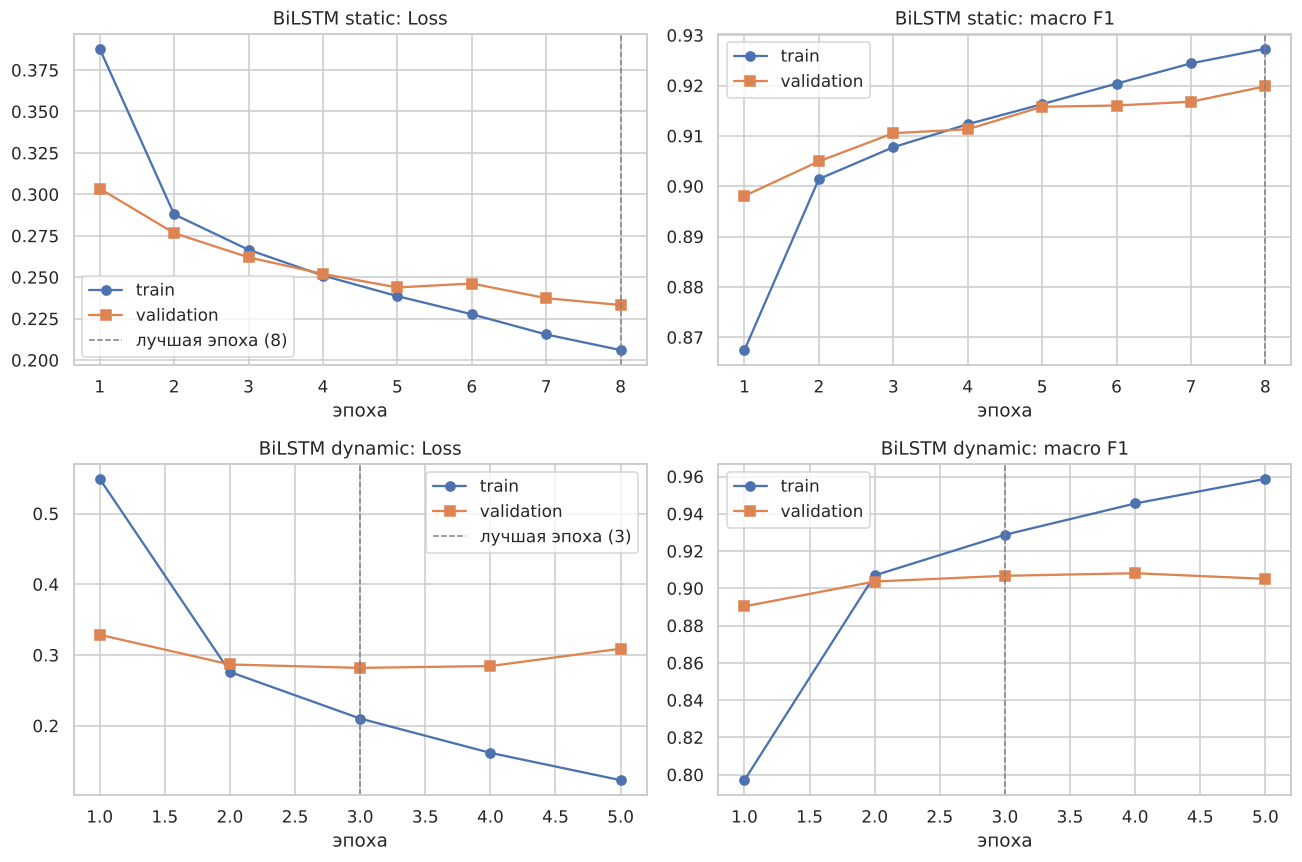

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for row, name in enumerate(rnn):
    model, hist, best_epoch, _ = rnn[name]
    ep = range(1, len(hist['train_loss']) + 1)
    axes[row, 0].plot(ep, hist['train_loss'], 'o-', label='train')
    axes[row, 0].plot(ep, hist['val_loss'], 's-', label='validation')
    axes[row, 0].axvline(best_epoch, color='gray', ls='--', lw=1, label=f'лучшая эпоха ({best_epoch})')
    axes[row, 0].set_title(f'{name}: Loss'); axes[row, 0].set_xlabel('эпоха'); axes[row, 0].legend()
    axes[row, 1].plot(ep, hist['train_f1'], 'o-', label='train')
    axes[row, 1].plot(ep, hist['val_f1'], 's-', label='validation')
    axes[row, 1].axvline(best_epoch, color='gray', ls='--', lw=1)
    axes[row, 1].set_title(f'{name}: macro F1'); axes[row, 1].set_xlabel('эпоха'); axes[row, 1].legend()
plt.tight_layout()
plt.show()

In [ ]:
rows, f1_by_name = [], {}
for name in rnn:
    model, hist, best_epoch, train_time = rnn[name]
    pred = predict_logits(model, X_te).argmax(1).numpy() + 1
    m = evaluate(y_test, pred)
    f1_by_name[name] = m['f1']
    rows.append({'модель': name, 'Precision': m['precision'], 'Recall': m['recall'], 'F1': m['f1'],
                 'Accuracy': m['accuracy'], 'лучшая эпоха': best_epoch, 'эпох всего': len(hist['train_loss']),
                 'время обучения, с': round(train_time)})
display(pd.DataFrame(rows).set_index('модель').round(4))

best_name = max(f1_by_name, key=f1_by_name.get)
pred_best = predict_logits(rnn[best_name][0], X_te).argmax(1).numpy() + 1
print(f'Отчёт по классам для лучшей сети ({best_name}):')
print(classification_report(y_test, pred_best, target_names=[LABEL_MAP[i] for i in (1, 2, 3, 4)], digits=4))

,Precision,Recall,F1,Accuracy,лучшая эпоха,эпох всего,"время обучения, с"
модель,,,,,,,
BiLSTM static,0.9254,0.9246,0.9244,0.9246,8,8,768
BiLSTM dynamic,0.9110,0.9104,0.9105,0.9104,3,5,516


Отчёт по классам для лучшей сети (BiLSTM static):
              precision    recall  f1-score   support

       World     0.9449    0.9118    0.9281      6000
      Sports     0.9642    0.9843    0.9742      6000
    Business     0.9186    0.8672    0.8921      6000
    Sci/Tech     0.8737    0.9350    0.9033      6000

    accuracy                         0.9246     24000
   macro avg     0.9254    0.9246    0.9244     24000
weighted avg     0.9254    0.9246    0.9244     24000



Результаты на Test:

| Режим | Precision | Recall | Macro F1 | Эпох | Лучшая эпоха | Время обучения |
|---|---|---|---|---|---|---|
| BiLSTM static | 0,9254 | 0,9246 | 0,9244 | 8 | 8 | 768 с |
| BiLSTM dynamic | 0,9110 | 0,9104 | 0,9105 | 5 | 3 | 516 с |

Static лучше dynamic на 1,4 пункта. По графикам видно, что у dynamic после третьей эпохи validation loss растёт (0,282, затем 0,284, затем 0,309), а F1 на обучающей части доходит до 0,959 при 0,905 на validation: сеть переобучается. Early Stopping остановил обучение и вернул веса третьей эпохи. Скорее всего, данных просто не хватает, чтобы выучить 2,6 млн весов эмбеддингов, а в static эти векторы уже готовые.

У static Early Stopping не сработал: к восьмой эпохе validation loss ещё снижался, и обучение закончилось по лимиту эпох. Возможно, при большем лимите результат был бы чуть лучше, но я этого не проверяла.

Слабые классы такие же, как у SVM в третьей работе: Business (F1 0,892) и Sci/Tech (0,903), лучше всего Sports (0,974).

Static и LinearSVC различаются на 0,002 (0,9244 против 0,9225). Для одного запуска на 24 000 документах это примерно уровень погрешности, поэтому качество я считаю одинаковым.

## 5. Выбор трансформера

Датасет английский, поэтому `rubert` из примера в задании не подходит. Беру `distilbert-base-uncased`: это уменьшенный BERT (6 слоёв вместо 12, около 66 млн параметров), обученный на английском без учёта регистра. Для новостей регистр не важен, а модель легче и быстрее полного BERT, что удобно при ограниченных ресурсах.

Токенизатору BERT нужен текст с регистром и пунктуацией, поэтому очистку из шага 0 здесь не использую, только декодирую HTML-сущности и убираю теги.

In [11]:
MODEL_NAME = 'distilbert-base-uncased'
N_PER_CLASS = 4000      # подвыборка Train: по 4000 документов на класс, 16 000 всего
N_VAL_PER_CLASS = 500   # validation: по 500 на класс, не пересекается с обучающей
MAX_LEN_BERT = 64
BERT_EPOCHS = 3
BERT_LR = 5e-5
BERT_BS = 32

RE_ENT = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
def light_clean(text):
    text = RE_ENT.sub(r'&\1;', text)
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

parts = [train_df[train_df['label'] == l].sample(N_PER_CLASS + N_VAL_PER_CLASS, random_state=RANDOM_STATE) for l in (1, 2, 3, 4)]
bert_train = pd.concat([p.iloc[:N_PER_CLASS] for p in parts]).sample(frac=1, random_state=RANDOM_STATE)
bert_val = pd.concat([p.iloc[N_PER_CLASS:] for p in parts]).sample(frac=1, random_state=RANDOM_STATE)
print('Подвыборка для fine-tuning:', len(bert_train), ' validation:', len(bert_val), ' test (весь):', len(test_df))
print(bert_train['category'].value_counts().to_dict())
print('Пример текста для модели:', light_clean(bert_train['text'].iloc[0])[:150])

Подвыборка для fine-tuning: 16000  validation: 2000  test (весь): 24000
{'Business': 4000, 'Sports': 4000, 'World': 4000, 'Sci/Tech': 4000}
Пример текста для модели: Tupperware Posts Profit, Narrows '04 View NEW YORK (Reuters) - Tupperware Corp. TUP.N on Monday posted a third-quarter profit versus break-even a year


## 6. Fine-tuning

`AutoModelForSequenceClassification` берёт предобученный DistilBERT и добавляет сверху классификационную голову на 4 класса (линейные слои над представлением токена `[CLS]`). Дообучаются все веса: и сам трансформер, и голова. Использую `Trainer`: он сам собирает батчи, считает loss, обновляет веса и после каждой эпохи оценивает модель на validation. В конце загружается лучшая по F1 эпоха.

Обучаю на сбалансированной подвыборке из 16 000 документов (это разрешено заданием), 3 эпохи, `lr=5e-5`, батч 32. Оцениваю на всём Test (24 000 документов), чтобы метрики были сравнимы с остальными моделями.

In [12]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)
print('Параметров в модели:', f'{sum(p.numel() for p in bert_model.parameters()):,}')


class TextDS(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer([light_clean(t) for t in texts], truncation=True, max_length=MAX_LEN_BERT)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i]) - 1
        return item

ds_train = TextDS(bert_train['text'], bert_train['label'])
ds_val = TextDS(bert_val['text'], bert_val['label'])
ds_test = TextDS(test_df['text'], test_df['label'])


def compute_metrics(eval_pred):
    pred = eval_pred.predictions.argmax(-1)
    m = evaluate(eval_pred.label_ids, pred)
    return {'precision': m['precision'], 'recall': m['recall'], 'f1': m['f1'], 'accuracy': m['accuracy']}


WARMUP_STEPS = int(0.1 * (len(ds_train) // BERT_BS) * BERT_EPOCHS)

args = TrainingArguments(
    output_dir='bert_out', num_train_epochs=BERT_EPOCHS, per_device_train_batch_size=BERT_BS,
    per_device_eval_batch_size=128, learning_rate=BERT_LR, weight_decay=0.01, warmup_steps=WARMUP_STEPS,
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model='f1',
    logging_strategy='epoch', report_to='none', fp16=torch.cuda.is_available(), seed=RANDOM_STATE)

trainer = Trainer(model=bert_model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)

Параметров в модели: 66,956,548


In [13]:
t0 = time.time()
trainer.train()
bert_time = time.time() - t0
print(f'Fine-tuning занял {bert_time:.0f} с')

log = pd.DataFrame(trainer.state.log_history)
epoch_table = pd.concat([
    log.dropna(subset=['loss'])[['epoch', 'loss']].rename(columns={'loss': 'train loss'}).set_index('epoch'),
    log.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_f1']].rename(
        columns={'eval_loss': 'val loss', 'eval_f1': 'val macro F1'}).set_index('epoch')], axis=1)
display(epoch_table.round(4))

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.437725,0.274106,0.909002,0.908000,0.907886,0.908000
2,0.190284,0.265416,0.919710,0.919500,0.919143,0.919500
3,0.103419,0.284142,0.921975,0.922000,0.921886,0.922000


Fine-tuning занял 135 с


,train loss,val loss,val macro F1
epoch,,,
1.0,0.4377,0.2741,0.9079
2.0,0.1903,0.2654,0.9191
3.0,0.1034,0.2841,0.9219


In [14]:
out = trainer.predict(ds_test)
pred_bert = out.predictions.argmax(-1) + 1
m_bert = evaluate(y_test, pred_bert)
print(pd.Series(m_bert).round(4).to_string())
print()
print(classification_report(y_test, pred_bert, target_names=[LABEL_MAP[i] for i in (1, 2, 3, 4)], digits=4))

precision    0.9266
recall       0.9264
f1           0.9265
accuracy     0.9264

              precision    recall  f1-score   support

       World     0.9388    0.9198    0.9292      6000
      Sports     0.9754    0.9773    0.9764      6000
    Business     0.8879    0.9038    0.8958      6000
    Sci/Tech     0.9045    0.9047    0.9046      6000

    accuracy                         0.9264     24000
   macro avg     0.9266    0.9264    0.9265     24000
weighted avg     0.9266    0.9264    0.9265     24000



По эпохам validation F1 растёт до последней (0,9079, 0,9191, 0,9219), хотя validation loss на третьей эпохе уже немного вырос (с 0,2654 до 0,2841): модель начинает слегка переобучаться, но на F1 это пока не сказывается. Для оценки загружена лучшая по F1 эпоха, то есть третья.

На Test macro F1 получился 0,9265 (Precision 0,9266, Recall 0,9264). Слабые классы те же, что у остальных моделей: Business (F1 0,896) и Sci/Tech (0,905), лучше всего Sports (0,976).

Дообучение заняло 135 секунд на GPU в Colab. При первой попытке на CPU Trainer оценил то же обучение примерно в 4,5 часа. Для сравнения я запускала fine-tuning и на подвыборке в 4 раза меньше (по 1000 документов на класс, 4 000 всего): macro F1 на Test получился 0,9109, обучение заняло 74 секунды.

## 7. Сводный бенчмарк

Результаты Naive Bayes и SVM перенесены из третьей работы (TF-IDF, лучшие параметры по кросс-валидации), остальные получены выше. Время обучения указано для самого классификатора, в скобках отдельно подготовка признаков (TF-IDF, Word2Vec). Замеры всех моделей, кроме DistilBERT, сделаны на CPU. DistilBERT обучался на GPU в Colab, поэтому по времени его нельзя напрямую сравнивать с остальными.

| Модель | Векторизация / Архитектура | Особенности | Precision | Recall | F1-Score | Время обучения |
|---|---|---|---|---|---|---|
| Naive Bayes | TF-IDF, 42 500 признаков | alpha = 0,1 | 0,9087 | 0,9088 | 0,9086 | 0,03 с (+2 с на TF-IDF) |
| SVM (LinearSVC) | TF-IDF, 42 500 признаков | C = 0,3, class_weight balanced | 0,9226 | 0,9227 | 0,9225 | 2,7 с (+2 с на TF-IDF) |
| Логистическая регрессия | среднее векторов Word2Vec (100) | C = 1 | 0,8935 | 0,8937 | 0,8935 | 2 с (+168 с на Word2Vec) |
| BiLSTM static | Embedding из Word2Vec, заморожен | 8 эпох | 0,9254 | 0,9246 | 0,9244 | 768 с (+162 с на Word2Vec) |
| BiLSTM dynamic | Embedding с нуля | Early Stopping, лучшая эпоха 3 из 5 | 0,9110 | 0,9104 | 0,9105 | 516 с (+162 с на Word2Vec) |
| DistilBERT fine-tuning | distilbert-base-uncased и линейная голова | 16 000 документов, 3 эпохи, GPU | 0,9266 | 0,9264 | 0,9265 | 135 с (на GPU) |

## 8. Вывод

По macro F1 модели расположились так: DistilBERT 0,9265, BiLSTM static 0,9244, LinearSVC 0,9225, BiLSTM dynamic 0,9105, Naive Bayes 0,9086, логистическая регрессия на усреднённых векторах 0,8935. Первые три отличаются друг от друга на 0,002-0,004, а это порядок погрешности оценки на 24 000 документах, поэтому заметного преимущества трансформера или рекуррентной сети над SVM на этих данных я не вижу.

Цена при этом очень разная. SVM на TF-IDF обучается за несколько секунд на CPU (около 5 с вместе с TF-IDF). BiLSTM static вместе с Word2Vec занимает около 930 с на CPU. DistilBERT дообучался 135 с, но на GPU, и это время нельзя прямо сравнивать с CPU-замерами остальных моделей: на CPU то же обучение, по оценке Trainer, заняло бы около 4,5 часа. Кроме того, для трансформера нужны GPU и загрузка предобученной модели (около 270 МБ), а для SVM хватает обычного процессора. Интересно, что DistilBERT получил своё качество, увидев только 16 000 документов из 96 000, на которых учились остальные модели. Скорее всего, в этом сказывается предобучение на большом корпусе. Но при 4 000 документах он уже уступает SVM, обученному на всём Train (0,9109 против 0,9225).

BiLSTM с обучаемым Embedding (dynamic) оказалась хуже SVM (0,9105) и намного дороже его: 86 тысяч документов мало, чтобы с нуля выучить векторы слов, и сеть переобучается. Готовые векторы Word2Vec в static-режиме эту проблему снимают. Логистическая регрессия на усреднённых векторах самая слабая (0,8935), потому что усреднение размывает характерные слова.

Классические методы здесь так хороши, потому что тема новости определяется ключевыми словами (`oil`, `nasa`, `baseball`, `iraq`), а TF-IDF хранит каждое слово отдельным признаком. Тексты короткие (в среднем 38 слов), порядок слов и дальний контекст почти не нужны, а именно их и добавляют BiLSTM и трансформер. Слабые классы у всех моделей одни и те же, Business и Sci/Tech. В третьей работе я разбирала причины: размытая граница классов и спорная разметка, и одной сменой модели это вряд ли исправить.

Итог: для тематической классификации новостей AG News по соотношению качества и затрат разумный выбор это TF-IDF с линейной моделью. Трансформер оправдан, если есть GPU и нужны лишние десятые доли процента, а также когда размеченных данных мало. Нейросетевые модели с учётом порядка слов были бы нужнее для задач, где важен контекст, например для тональности.